# Mountain

Summit forecast: the chalet's top panel (forecast for now with the 0° level, new snow and sunshine over the next 48 h, SLF avalanche bulletin), and a 39 h chart like the MeteoSwiss app: wind every 3 h, sunshine with sunrise and sunset, estimated new snow, rain and temperature.

Data: MeteoSwiss local forecast (OGD), point of interest.

In [1]:
import json
import localforecast as lf
import screens

In [2]:
# Find point ids: search by name (accents ignored), station abbreviation or postal code
lf.find_point("touno")

,point_id,point_type_id,point_name,station_abbr,postal_code,point_type_en,point_height_masl
5770,1119,3,Le Toûno,NaN,NaN,Point of Interest,3018.0


In [3]:
# ── Configuration ──────────────────────────────────────────────
POINT = (1119, 3)         # Le Toûno, point of interest, 3018 m
SLF_REGION = "CH-4124"    # Val d'Anniviers
SLF_ACTIVE_AT = None      # e.g. "2026-02-15T10:00:00Z" to try the layout
HOURS = 39       # chart: 39 h from the last 00:00 / 12:00
# ───────────────────────────────────────────────────────────────

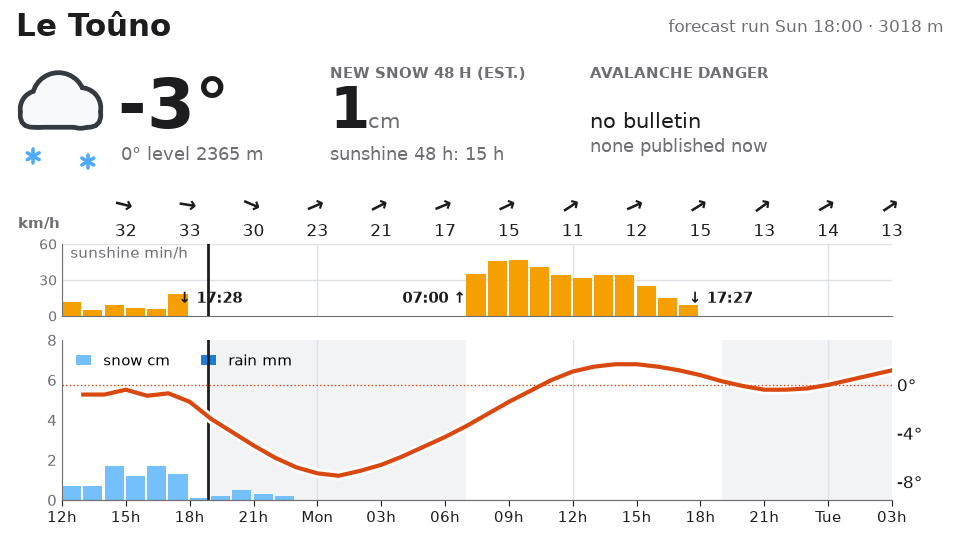

In [4]:
run, data = lf.fetch([POINT], lf.MOUNTAIN_PARAMS)
hourly, _ = data[POINT]
bulletin = lf.slf_bulletin(SLF_REGION, active_at=SLF_ACTIVE_AT)
view = lf.mountain_view(run, hourly, lf.point_info(POINT), bulletin, hours=HOURS)
screens.render(screens.mountain, view, colour=True)

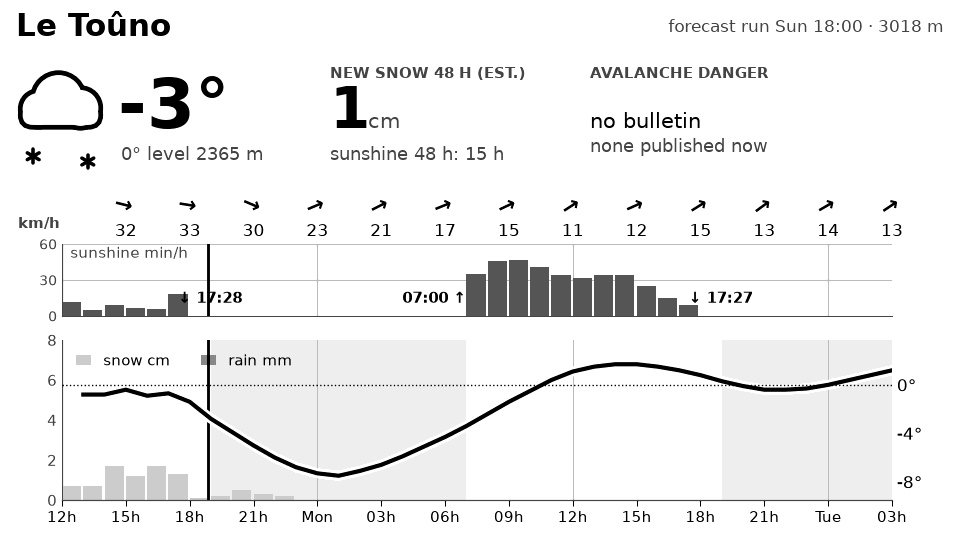

In [5]:
# As on the LilyGO T5 4.7" e-paper: 960×540, 16 grey levels
img = screens.render(screens.mountain, view)
img

In [6]:
# The payload a display would receive
print(f"{len(json.dumps(view, separators=(',', ':')))} bytes as JSON, "
      f"{len(screens.epd_buffer(img)):,} bytes as a 4-bit frame buffer")
print(json.dumps(view, indent=1)[:1500])

2816 bytes as JSON, 259,200 bytes as a 4-bit frame buffer
{
 "view": "mountain",
 "name": "Le To\u00fbno",
 "alt": 3018.0,
 "run": "2026-10-25T18:00:00+01:00",
 "now": {
  "time": "2026-10-25T19:00:00+01:00",
  "temp": -2.8,
  "icon": 111,
  "freezing_m": 2365
 },
 "snow_next_cm": 1.3,
 "sun_next_h": 15.0,
 "hourly": {
  "time": [
   "2026-10-25T13:00:00+01:00",
   "2026-10-25T14:00:00+01:00",
   "2026-10-25T15:00:00+01:00",
   "2026-10-25T16:00:00+01:00",
   "2026-10-25T17:00:00+01:00",
   "2026-10-25T18:00:00+01:00",
   "2026-10-25T19:00:00+01:00",
   "2026-10-25T20:00:00+01:00",
   "2026-10-25T21:00:00+01:00",
   "2026-10-25T22:00:00+01:00",
   "2026-10-25T23:00:00+01:00",
   "2026-10-26T00:00:00+01:00",
   "2026-10-26T01:00:00+01:00",
   "2026-10-26T02:00:00+01:00",
   "2026-10-26T03:00:00+01:00",
   "2026-10-26T04:00:00+01:00",
   "2026-10-26T05:00:00+01:00",
   "2026-10-26T06:00:00+01:00",
   "2026-10-26T07:00:00+01:00",
   "2026-10-26T08:00:00+01:00",
   "2026-10-26T09:00:00+01: